In [1]:
from rdkit import Chem
from rdkit import RDLogger
import numpy as np
import csv
import joblib
import sys
import time
from anytree import Node, RenderTree
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint
import xgboost

In [30]:
# Load the model
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')

In [28]:
clf = joblib.load('models/v12/xg_model.pkl')

In [37]:
sm_smiles = 'O.CC(C)=CCCC(C)=C[CH2+]'
end_smiles = '[OH3+].CC1=CCC(CC1)C(=C)C'
sm = Chem.MolFromSmiles(sm_smiles)
end = Chem.MolFromSmiles(end_smiles)

sm_node = Node("SM", mol=sm)

In [49]:
force_depth = True
depth_limit = 5
step_no = 0
product_nodes = []
times_per_layer = []
nodes = [sm_node]
signal_break = False
unique_id = 0
RDLogger.DisableLog('rdApp.*') 
while step_no < depth_limit:
    start_t = time.time()
    print(f'step no {step_no}')
    nodes_to_next = []
    for int in nodes:
        try:
            product_mols, mechs, mol_inp  = execute_step("Placeholder", True, False, int.mol, False)
        except Exception as e:
            continue
        for i, product in enumerate(product_mols):
            fp = np.array(make_fingerprint(mol_inp, mechs[i]))
            pred = clf.predict(fp.reshape(1,-1))[0]
            try:
                inchi1 = Chem.MolToInchi(product, options='FixedH')
                inchi2 = Chem.MolToInchi(end, options='FixedH')
            except Exception as e:
                print(f'Error processing product {i}: {e}')
                continue
            if inchi1 == inchi2:
                print('Found the target molecule!')
                print(f'The final step (mol {unique_id}) was predicted: {pred}')
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                unique_id += 1
                product_nodes.append(new_node)
                if not force_depth:
                    signal_break = True
                    break
            elif pred == 1:
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                unique_id += 1
                nodes_to_next.append(new_node)
        if signal_break:
            break
    if signal_break:
        print("we breaking")
        break
    nodes = nodes_to_next
    step_no += 1
    end_t = time.time()
    times_per_layer.append(end_t - start_t)

print("search is over")

       


step no 0
step no 1
Found the target molecule!
The final step (mol 2) was predicted: 1
step no 2
step no 3
Found the target molecule!
The final step (mol 6) was predicted: 1
step no 4
search is over


In [42]:
for i, dur in enumerate(times_per_layer):
    print(f'Layer {i+1} took {dur:.2f} seconds')

Layer 1 took 0.05 seconds
Layer 2 took 0.61 seconds
Layer 3 took 6.79 seconds
Layer 4 took 103.54 seconds


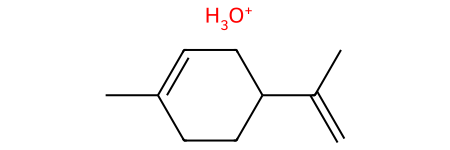

In [40]:
product_nodes[1].mol

In [34]:
def visualise_tree(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 300), legends=[f"Mol {i}" for i in range(len(mols))])

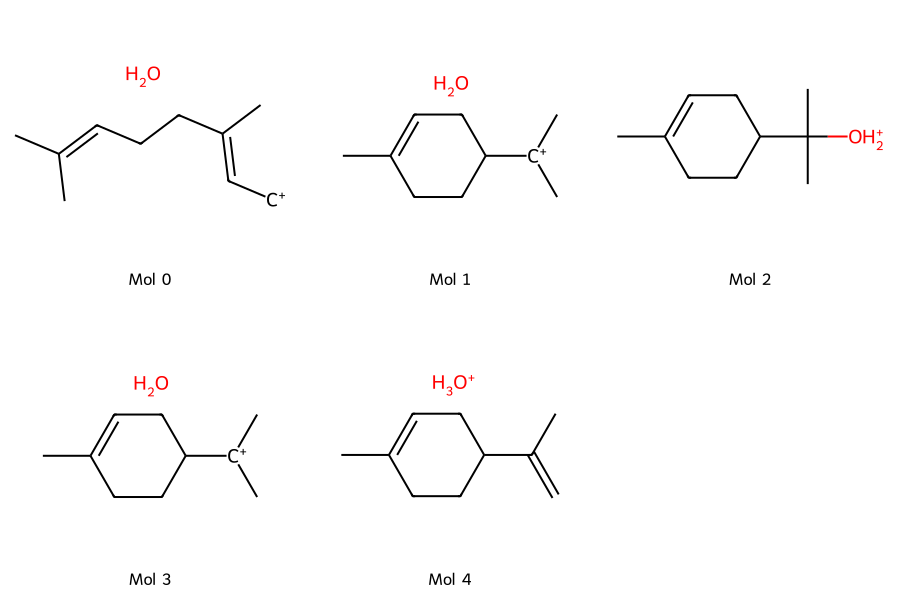

In [51]:
visualise_tree(product_nodes[1])

In [36]:
for pre, fill, node in RenderTree(sm_node):
    print(f"{pre}{node.name} - {Chem.MolToSmiles(node.mol)}")
    #if hasattr(node, 'mech'):
    #    print(f"{pre}Mechanism: {node.mech}")
    #else:
    #    print(f"{pre}Mechanism: None")

SM - O.[CH2+]C=C(C)CCC=C(C)C
├── Mol 0 - CC(C)=CCCC(C)=CC[OH2+]
├── Mol 1 - CC1=CCC([C+](C)C)CC1.O
│   ├── Mol 2 - C=C(C)C1CC=C(C)CC1.[OH3+]
│   │   └── Mol 5 - CC1=CCC([C+](C)C)CC1.O
│   │       ├── Mol 7 - C=C(C)C1CC=C(C)CC1.[OH3+]
│   │       │   └── Mol 13 - CC1=CCC([C+](C)C)CC1.O
│   │       ├── Mol 8 - CC1=CCC(C(C)(C)[OH2+])CC1
│   │       │   └── Mol 14 - CC1=CCC([C+](C)C)CC1.O
│   │       └── Mol 9 - CC1=CCC(=C(C)C)CC1.[OH3+]
│   ├── Mol 3 - CC1=CCC(C(C)(C)[OH2+])CC1
│   │   └── Mol 6 - CC1=CCC([C+](C)C)CC1.O
│   │       ├── Mol 10 - C=C(C)C1CC=C(C)CC1.[OH3+]
│   │       │   └── Mol 15 - CC1=CCC([C+](C)C)CC1.O
│   │       ├── Mol 11 - CC1=CCC(C(C)(C)[OH2+])CC1
│   │       │   └── Mol 16 - CC1=CCC([C+](C)C)CC1.O
│   │       └── Mol 12 - CC1=CCC(=C(C)C)CC1.[OH3+]
│   └── Mol 4 - CC1=CCC(=C(C)C)CC1.[OH3+]
├── Mol 0 - CC(C)=CCCC(C)=CC[OH2+]
└── Mol 1 - CC1=CCC([C+](C)C)CC1.O
    ├── Mol 2 - C=C(C)C1CC=C(C)CC1.[OH3+]
    │   └── Mol 5 - CC1=CCC([C+](C)C)CC1.O
    │       ├── Mol 7 -

In [11]:
new_node

Node('/SM/Mol 1/Mol 3/Mol 5/Mol 7/Mol 9', mech=[10, None, 2, None, 0], mol=<rdkit.Chem.rdchem.Mol object at 0x7f86e2e3eea0>)

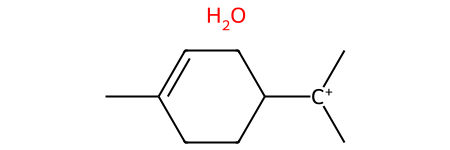

In [12]:
new_node.mol

In [13]:
execute_step('CC1=CCC([C+](C)C)CC1.O', True, False, None, False)

[9, 10, 4, 5, None]
[0, 10, 5, None, None]
[9, 10, 6, 5, None]
[1, 10, 1, None, 2]
[1, 10, 2, None, 1]
[9, 1, 4, 5, None]
[9, 2, 4, 5, None]
[1, 1, 5, 2, None]
[1, 2, 5, 1, None]
[9, 1, 6, 5, None]
[9, 2, 6, 5, None]
[5, 1, 10, 2, None]
[5, 2, 10, 1, None]


([<rdkit.Chem.rdchem.Mol at 0x7f86c92051c0>,
 [[9, 10, 4, 5, None],
  [0, 10, 5, None, None],
  [9, 10, 6, 5, None],
  [1, 10, 1, None, 2],
  [1, 10, 2, None, 1],
  [9, 1, 4, 5, None],
  [9, 2, 4, 5, None],
  [1, 1, 5, 2, None],
  [1, 2, 5, 1, None],
  [9, 1, 6, 5, None],
  [9, 2, 6, 5, None],
  [5, 1, 10, 2, None],
  [5, 2, 10, 1, None]],
 <rdkit.Chem.rdchem.Mol at 0x7f86c9204ba0>)

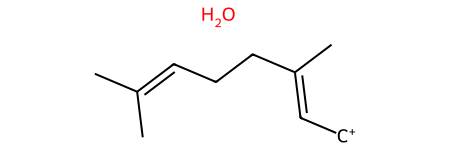

In [14]:
sm

In [15]:
mols, mechs, mol_inp = execute_step('O.CC(C)=CCCC(C)=C[CH2+]', True, False, None, False)

[9, 0, 9, 10, None]
[0, 0, 10, None, None]
[1, 0, 2, None, 4]
[1, 0, 4, None, 2]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 2, 0, 4, None]
[5, 4, 0, 2, None]
[9, 2, 9, 10, None]
[9, 4, 9, 10, None]
[1, 2, 10, 4, None]
[1, 4, 10, 2, None]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 9, 10, None]
[1, 7, 10, 9, None]
[1, 9, 10, 7, None]
[3, 2, 7, 4, 9]
[3, 4, 7, 2, 9]
[3, 2, 9, 4, 7]
[3, 4, 9, 2, 7]
[3, 7, 2, 9, 4]
[3, 9, 2, 7, 4]
[3, 7, 4, 9, 2]
[3, 9, 4, 7, 2]


In [24]:
mols, mechs, mol_inp = execute_step('P', True, False, b, False)

[9, 0, 1, 2, None]
[0, 0, 2, None, None]
[9, 0, 4, 2, None]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 1, 2, None]
[9, 9, 1, 2, None]
[1, 7, 2, 9, None]
[1, 9, 2, 7, None]
[9, 7, 4, 2, None]
[9, 9, 4, 2, None]


In [16]:
for i, mol in enumerate(mols):
    fp = np.array(make_fingerprint(mol_inp, mechs[i]))
    if clf.predict(fp.reshape(1,-1))[0]==1:
        print(f'Predicted product {i} is a valid reaction product')

Predicted product 1 is a valid reaction product
Predicted product 11 is a valid reaction product


In [17]:
b = Chem.Mol(mols[11])

In [18]:
clf.predict(fp.reshape(1,-1))

array([0])

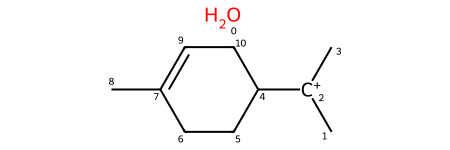

In [23]:
b

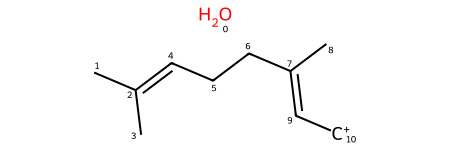

In [22]:
mol_inp

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True